In [24]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [43]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [51]:
weight = 0.3
bias = 0.9
x = torch.arange(0,1,0.01).unsqueeze(dim=1)
y = weight*x+bias
split = int(0.8*len(x))
X_train,X_test = x[:split],x[split:]
y_train,y_test = y[:split],y[split:]

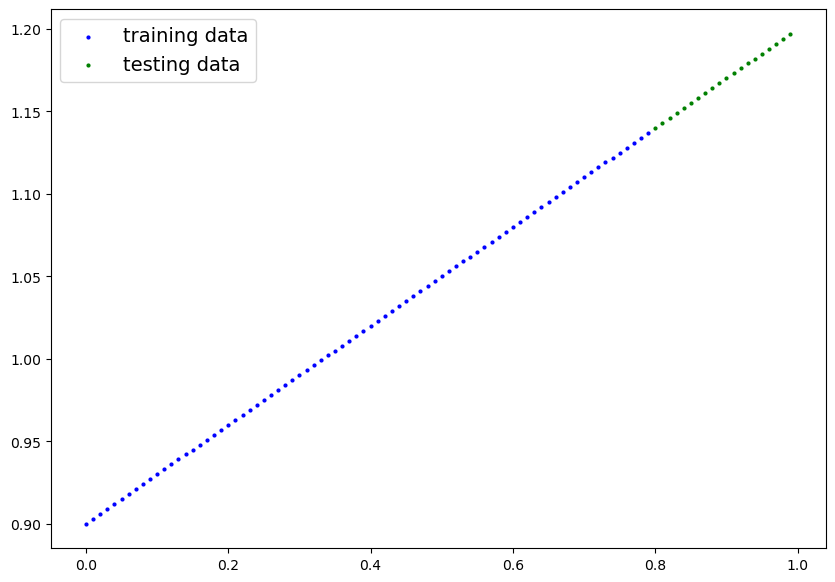

In [75]:
def plot_predictions(X_train,X_test,y_train,y_test,predictions=None):
    plt.figure(figsize=(10,7))
    plt.scatter(X_train,y_train,c="b",s=4,label="training data")
    plt.scatter(X_test,y_test,c="g",s=4,label="testing data")
    if predictions is not None:
        plt.scatter(X_test,predictions,c="r",s=4,label="predicted data")
    plt.legend(prop={"size":14})

plot_predictions(X_train,X_test,y_train,y_test) 

In [58]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(data = torch.rand(1,dtype=torch.float,requires_grad=True))
        self.bias = nn.Parameter(data=torch.rand(1,dtype=torch.float,requires_grad=True))
    def forward(self,x:torch.Tensor) -> torch.Tensor:
        return self.weight*x+self.bias
    

In [61]:
torch.manual_seed(234)
model = LinearRegressionModel()

In [62]:
model.state_dict()

OrderedDict([('weight', tensor([0.9276])), ('bias', tensor([0.5817]))])

In [56]:
loss_fn = nn.L1Loss()

In [66]:
optimizer = torch.optim.SGD(params=model.parameters(),lr=0.001)

In [68]:
torch.manual_seed(3124)
epochs = 300
training_loss =[]
testing_loss=[]
for epoch in range(epochs):
    model.train()
    y_pred = model(X_train)
    loss = loss_fn(y_pred,y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if epoch % 20 == 0:
        model.eval()
        with torch.inference_mode():
            test_pred = model(X_test)
            test_loss = loss_fn(test_pred,y_test)
        
        print(f'epoch: {epoch}, training loss: {loss}, testing loss: {test_loss}')
    

epoch: 0, training loss: 0.12015221267938614, testing loss: 0.2663699984550476
epoch: 20, training loss: 0.11940453946590424, testing loss: 0.26622921228408813
epoch: 40, training loss: 0.11865687370300293, testing loss: 0.2660883963108063
epoch: 60, training loss: 0.1179390549659729, testing loss: 0.2654605507850647
epoch: 80, training loss: 0.11723659187555313, testing loss: 0.2646239101886749
epoch: 100, training loss: 0.11653415858745575, testing loss: 0.26378732919692993
epoch: 120, training loss: 0.11583171039819717, testing loss: 0.26295068860054016
epoch: 140, training loss: 0.11512929201126099, testing loss: 0.26211410760879517
epoch: 160, training loss: 0.11442682892084122, testing loss: 0.261277437210083
epoch: 180, training loss: 0.11372438818216324, testing loss: 0.2604408264160156
epoch: 200, training loss: 0.11302193254232407, testing loss: 0.25960418581962585
epoch: 220, training loss: 0.11231950670480728, testing loss: 0.25876760482788086
epoch: 240, training loss: 0.1

In [72]:
model.eval()
with torch.inference_mode():
    test_pred = model(X_test)
test_pred
    

tensor([[1.3414],
        [1.3498],
        [1.3582],
        [1.3667],
        [1.3751],
        [1.3836],
        [1.3920],
        [1.4004],
        [1.4089],
        [1.4173],
        [1.4258],
        [1.4342],
        [1.4426],
        [1.4511],
        [1.4595],
        [1.4679],
        [1.4764],
        [1.4848],
        [1.4933],
        [1.5017]])

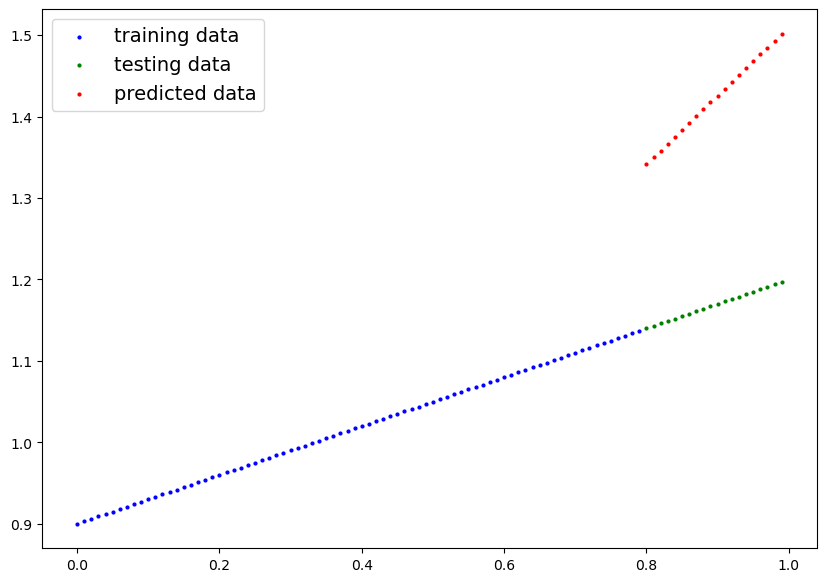

In [76]:
plot_predictions(X_train,X_test,y_train,y_test,test_pred)

In [80]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)
MODEL_NAME ="pytorch_1"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME
torch.save(obj=model.state_dict(),f=MODEL_SAVE_PATH)

In [81]:
loaded_model = LinearRegressionModel()
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
loaded_model.to(device)

LinearRegressionModel()

In [82]:
loaded_model.eval()
with torch.inference_mode():
    pred = loaded_model(X_test)
pred

tensor([[1.3414],
        [1.3498],
        [1.3582],
        [1.3667],
        [1.3751],
        [1.3836],
        [1.3920],
        [1.4004],
        [1.4089],
        [1.4173],
        [1.4258],
        [1.4342],
        [1.4426],
        [1.4511],
        [1.4595],
        [1.4679],
        [1.4764],
        [1.4848],
        [1.4933],
        [1.5017]])

In [85]:
test_pred - pred

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])